PROJECT TITLE

Marketing Campaign Data Analysis using Pandas, Matplotlib, and Seaborn

1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV file
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)

# Display the dataset
print(df.head())

   Campaign_ID              Company Campaign_Type Target_Audience Duration  \
0            1             TechCorp         Email     Women 25-34  30 days   
1            2  Innovate Industries    Influencer     Women 35-44  45 days   
2            3       NexGen Systems  Social Media     Women 25-34  45 days   
3            4  Innovate Industries         Email     Women 25-34  45 days   
4            5  Data Tech Solutions    Influencer       Men 25-34  30 days   

  Channel_Used  Conversion_Rate  Acquisition_Cost     ROI          Location  \
0     Facebook         5.294194              9344   62.94           Houston   
1   Google Ads         3.326375              8783   10.67  Washington, D.C.   
2    Instagram         4.056375              9111   73.20             Miami   
3    Instagram         4.496375              7420   60.92           Seattle   
4   Google Ads         4.405930              2146  138.82           Chicago   

  Language  Clicks  Impressions  Engagement_Score  Custo

2. Descriptive Analysis

In [2]:
# First five rows
print("First five rows:")
print(df.head())

# Number of rows and columns
print("\nDataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Dataset information
print("\nDataset information:")
df.info()

# Descriptive statistics for numerical columns
print("\nDescriptive statistics:")
print(df.describe())

First five rows:
   Campaign_ID              Company Campaign_Type Target_Audience Duration  \
0            1             TechCorp         Email     Women 25-34  30 days   
1            2  Innovate Industries    Influencer     Women 35-44  45 days   
2            3       NexGen Systems  Social Media     Women 25-34  45 days   
3            4  Innovate Industries         Email     Women 25-34  45 days   
4            5  Data Tech Solutions    Influencer       Men 25-34  30 days   

  Channel_Used  Conversion_Rate  Acquisition_Cost     ROI          Location  \
0     Facebook         5.294194              9344   62.94           Houston   
1   Google Ads         3.326375              8783   10.67  Washington, D.C.   
2    Instagram         4.056375              9111   73.20             Miami   
3    Instagram         4.496375              7420   60.92           Seattle   
4   Google Ads         4.405930              2146  138.82           Chicago   

  Language  Clicks  Impressions  Engage

B. Data exploration

In [3]:
# Number of unique campaign IDs
print("Unique Campaign IDs:", df['Campaign_ID'].nunique())

# Unique locations
print("\nUnique Locations:")
print(df['Location'].unique())

# Unique customer segments
print("\nUnique Customer Segments:")
print(df['Customer_Segment'].unique())

# Count each campaign type
print("\nCampaign Type Counts:")
print(df['Campaign_Type'].value_counts())

# Count each channel
print("\nChannel Counts:")
print(df['Channel_Used'].value_counts())

Unique Campaign IDs: 22029

Unique Locations:
['Houston' 'Washington, D.C.' 'Miami' 'Seattle' 'Chicago' 'Los Angeles'
 'Atlanta' 'Dallas' 'New York' 'San Francisco']

Unique Customer Segments:
['Tech Enthusiasts' 'Foodies' 'Fashionistas' 'Outdoor Adventurers'
 'Health & Wellness']

Campaign Type Counts:
Campaign_Type
Display         4450
Search          4441
Social Media    4412
Email           4388
Influencer      4338
Name: count, dtype: int64

Channel Counts:
Channel_Used
Facebook      3742
Google Ads    3694
Website       3688
Instagram     3649
YouTube       3632
Email         3624
Name: count, dtype: int64


3. Exploratory Data Analysis (EDA) and Visualization

In [4]:
# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')

# Convert duration strings such as "30 days" to numeric values
df['Duration_Days'] = pd.to_numeric(
    df['Duration'].astype(str).str.extract(r'(\d+)', expand=False),
    errors='coerce'
)

# Set a consistent plotting style
sns.set_theme(style="whitegrid", palette="Set2")

A. Campaign performance

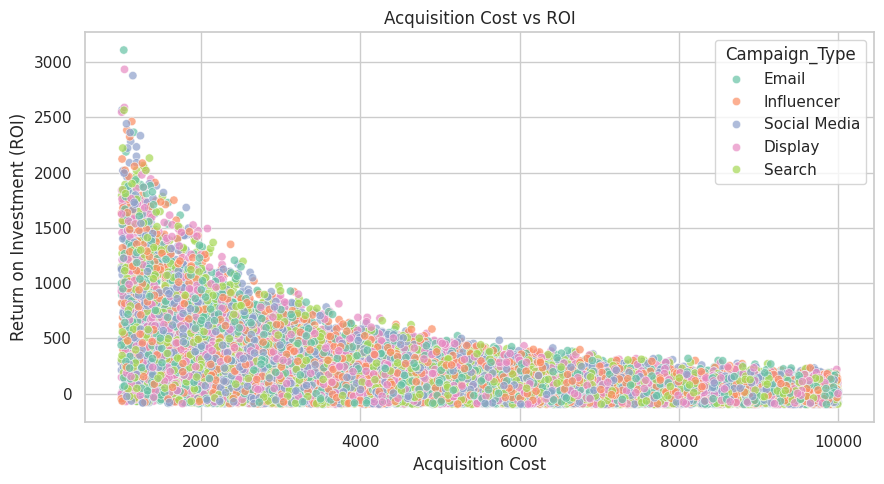

In [5]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Acquisition_Cost',
    y='ROI',
    hue='Campaign_Type',
    alpha=0.7
)

plt.title('Acquisition Cost vs ROI')
plt.xlabel('Acquisition Cost')
plt.ylabel('Return on Investment (ROI)')
plt.tight_layout()
plt.show()

2. Bar chart: Average Conversion Rate by Channel and Campaign Type

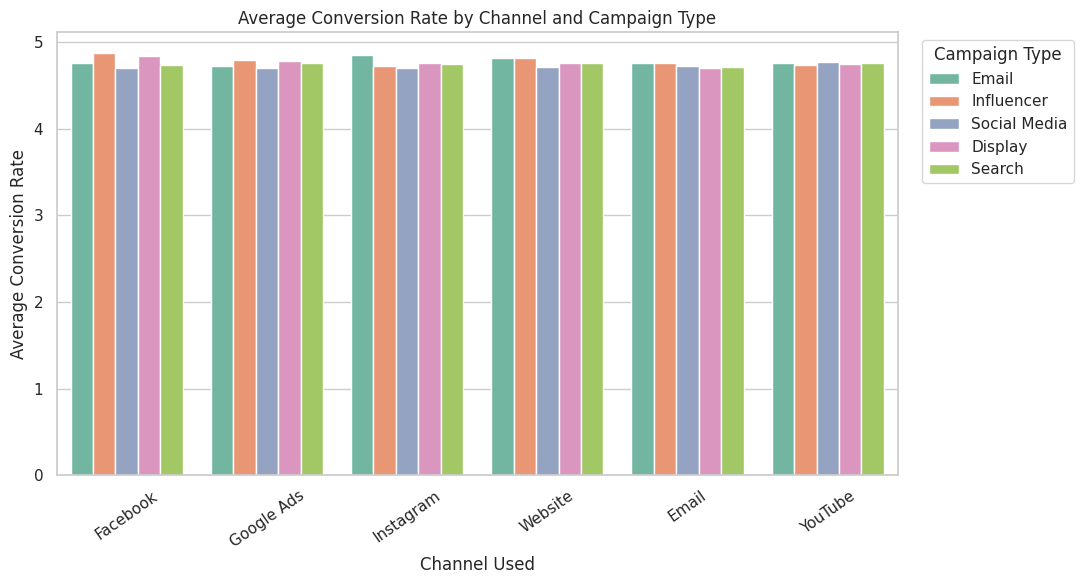

In [6]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df,
    x='Channel_Used',
    y='Conversion_Rate',
    hue='Campaign_Type',
    errorbar=None
)

plt.title('Average Conversion Rate by Channel and Campaign Type')
plt.xlabel('Channel Used')
plt.ylabel('Average Conversion Rate')
plt.xticks(rotation=35)
plt.legend(title='Campaign Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

3. Box plot: Engagement Score by Campaign Type

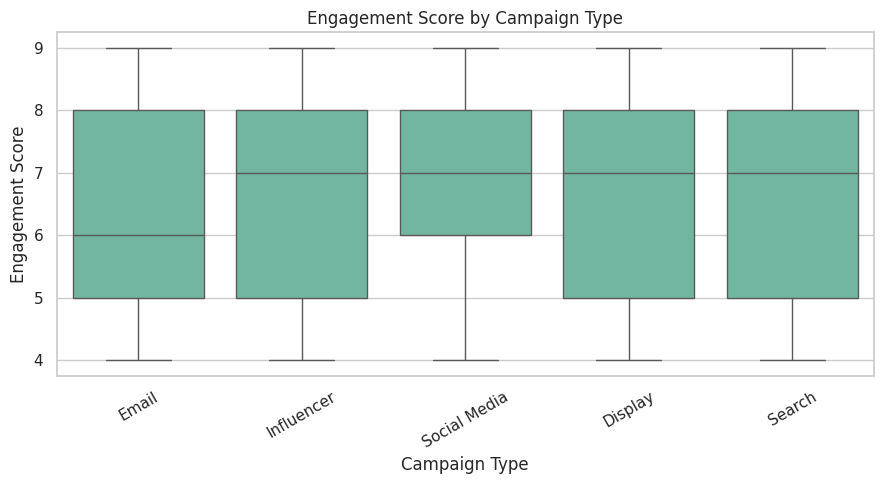

In [7]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Campaign_Type',
    y='Engagement_Score'
)

plt.title('Engagement Score by Campaign Type')
plt.xlabel('Campaign Type')
plt.ylabel('Engagement Score')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

4. Bar chart: Average ROI by Company


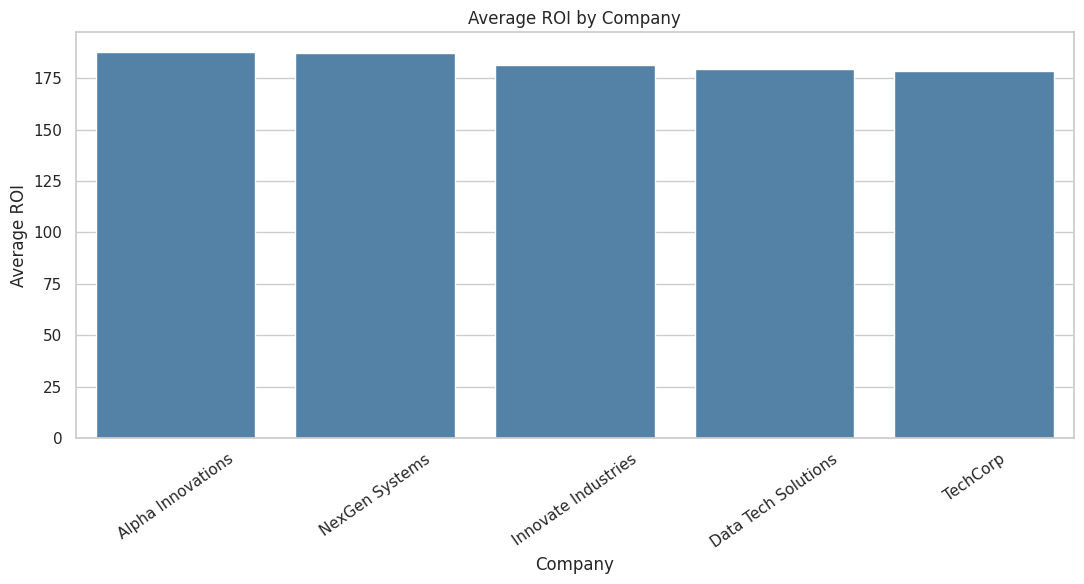

               Company         ROI
0    Alpha Innovations  187.802897
3       NexGen Systems  187.216772
2  Innovate Industries  181.513559
1  Data Tech Solutions  179.493878
4             TechCorp  178.355158


In [8]:
company_roi = (
    df.groupby('Company', as_index=False)['ROI']
      .mean()
      .sort_values('ROI', ascending=False)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=company_roi,
    x='Company',
    y='ROI',
    color='steelblue',
    errorbar=None
)

plt.title('Average ROI by Company')
plt.xlabel('Company')
plt.ylabel('Average ROI')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print(company_roi)

5. Heatmap: Engagement Score and Conversion Rate

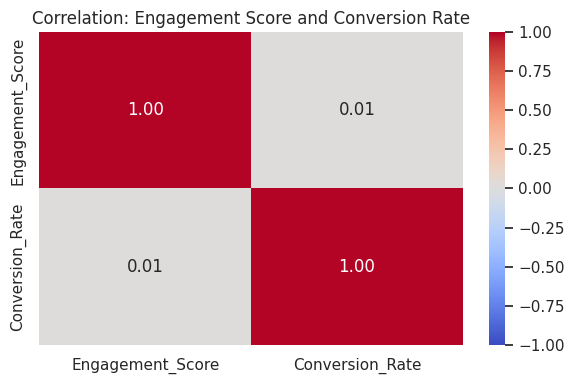

In [9]:
corr_data = df[['Engagement_Score', 'Conversion_Rate']].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    corr_data,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation: Engagement Score and Conversion Rate')
plt.tight_layout()
plt.show()

B. Customer segmentation

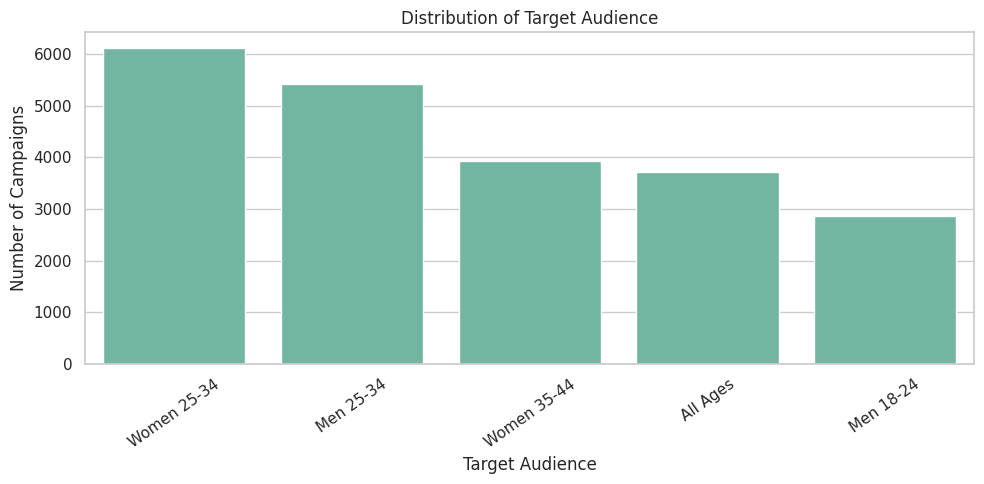

In [10]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Target_Audience',
    order=df['Target_Audience'].value_counts().index
)

plt.title('Distribution of Target Audience')
plt.xlabel('Target Audience')
plt.ylabel('Number of Campaigns')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

7. Bar chart: Highest Conversion-Rate Customer Segment by Language

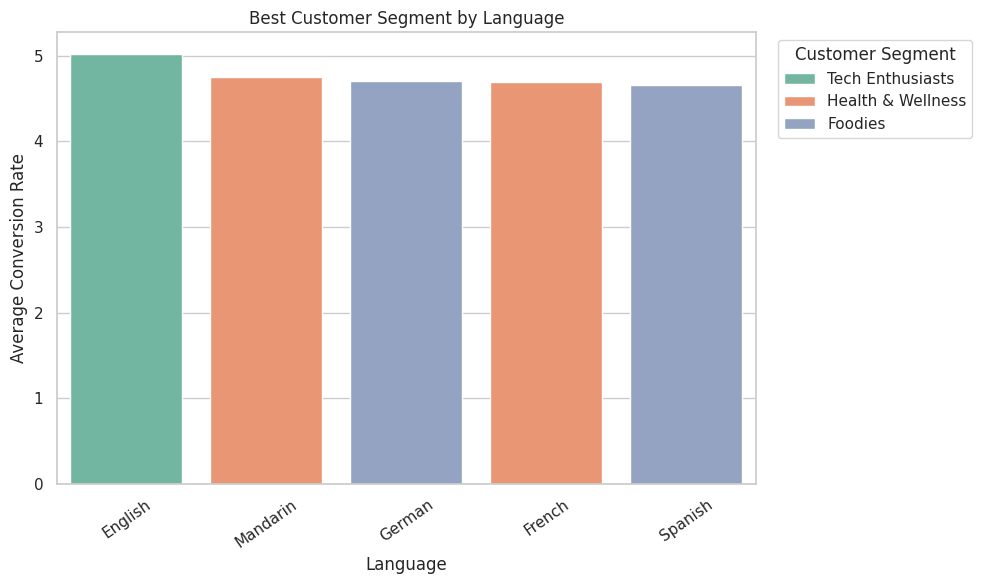

    Language   Customer_Segment  Conversion_Rate
4    English   Tech Enthusiasts         5.022731
17  Mandarin  Health & Wellness         4.756125
11    German            Foodies         4.705430
7     French  Health & Wellness         4.689704
21   Spanish            Foodies         4.663610


In [11]:
# Calculate average conversion rate for each language and segment
segment_language = (
    df.groupby(['Language', 'Customer_Segment'], as_index=False)
      ['Conversion_Rate'].mean()
)

# Select the highest-converting segment for each language
best_segments = (
    segment_language.loc[
        segment_language.groupby('Language')['Conversion_Rate'].idxmax()
    ]
    .sort_values('Conversion_Rate', ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=best_segments,
    x='Language',
    y='Conversion_Rate',
    hue='Customer_Segment',
    dodge=False
)

plt.title('Best Customer Segment by Language')
plt.xlabel('Language')
plt.ylabel('Average Conversion Rate')
plt.xticks(rotation=35)
plt.legend(title='Customer Segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print(best_segments)

9. Bar chart: Average Conversion Rate by Language

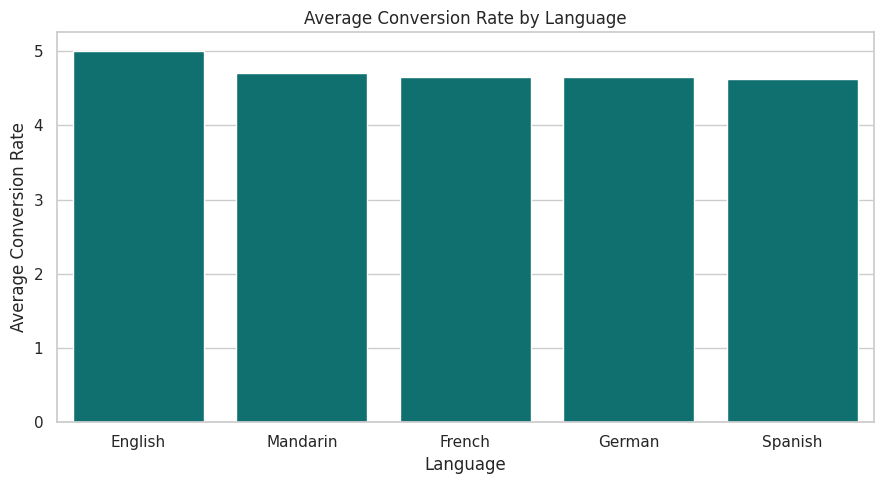

   Language  Conversion_Rate
0   English         5.005043
3  Mandarin         4.701252
1    French         4.647769
2    German         4.647514
4   Spanish         4.630547


In [12]:
language_conversion = (
    df.groupby("Language", as_index=False)["Conversion_Rate"]
    .mean()
    .sort_values("Conversion_Rate", ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=language_conversion,
    x="Language",
    y="Conversion_Rate",
    color="teal"
)

plt.title("Average Conversion Rate by Language")
plt.xlabel("Language")
plt.ylabel("Average Conversion Rate")
plt.tight_layout()
plt.show()

print(language_conversion)

C. Channel effectiveness
3.10 Engagement Score by Channel and Campaign Type

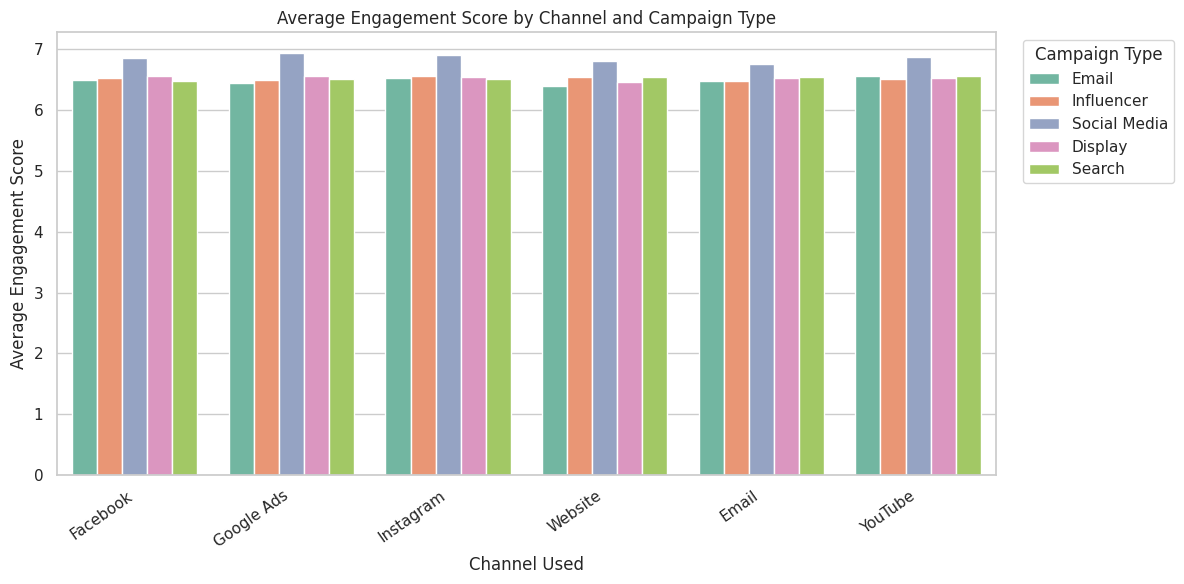

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Channel_Used",
    y="Engagement_Score",
    hue="Campaign_Type",
    errorbar=None
)

plt.title("Average Engagement Score by Channel and Campaign Type")
plt.xlabel("Channel Used")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Campaign Type", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

3.11 Total ROI by Channel — pie chart

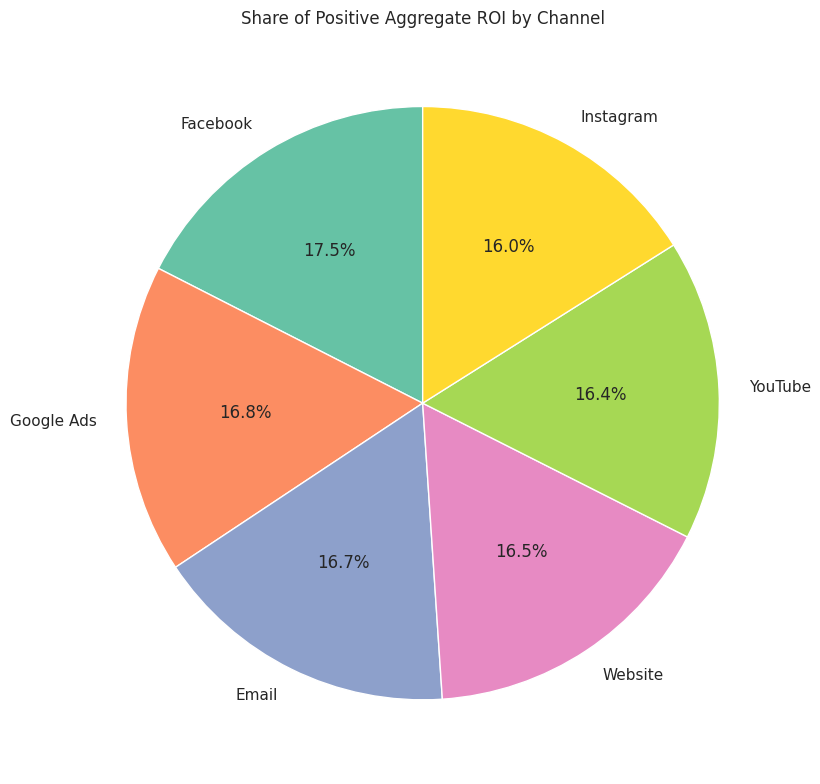

Total ROI by Channel:
Channel_Used
Facebook      704684.82
Google Ads    678232.24
Email         673804.39
Website       664577.42
YouTube       660542.33
Instagram     646462.11
Name: ROI, dtype: float64

Channels with non-positive aggregate ROI:
Series([], Name: ROI, dtype: float64)


In [14]:
channel_roi = df.groupby("Channel_Used")["ROI"].sum().sort_values(
    ascending=False
)

positive_channel_roi = channel_roi[channel_roi > 0]

plt.figure(figsize=(9, 8))

positive_channel_roi.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    ylabel=""
)

plt.title("Share of Positive Aggregate ROI by Channel")
plt.tight_layout()
plt.show()

print("Total ROI by Channel:")
print(channel_roi)

print("\nChannels with non-positive aggregate ROI:")
print(channel_roi[channel_roi <= 0])

3.12 Relationship between Clicks and Impressions by Channel

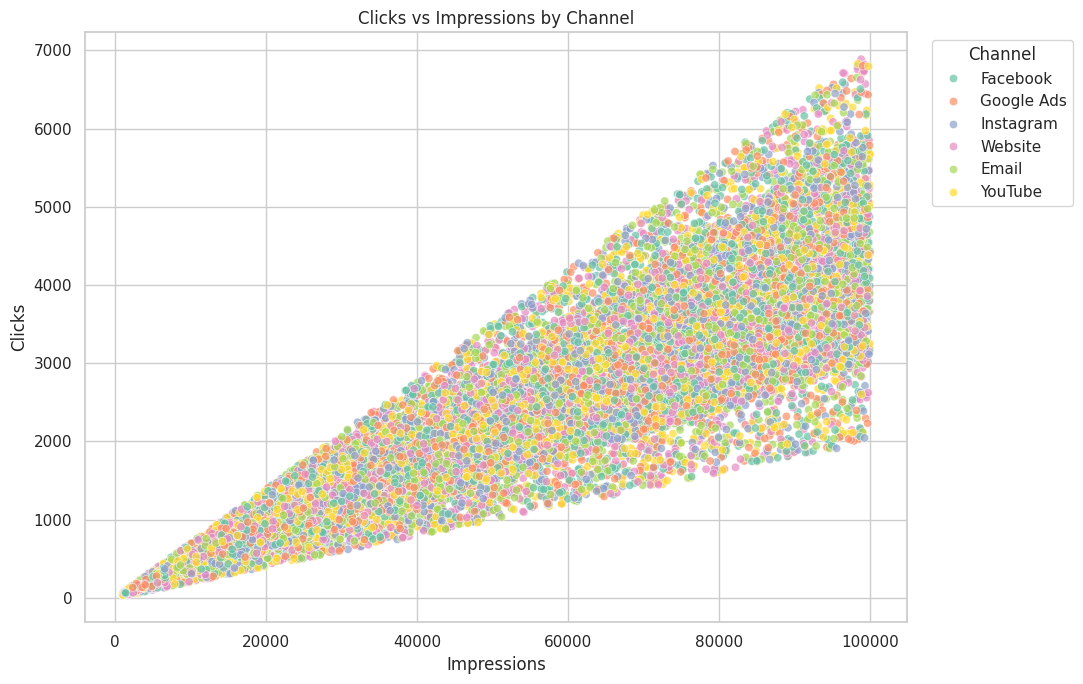

In [15]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="Impressions",
    y="Clicks",
    hue="Channel_Used",
    alpha=0.7
)

plt.title("Clicks vs Impressions by Channel")
plt.xlabel("Impressions")
plt.ylabel("Clicks")
plt.legend(title="Channel", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

D. Time-based analysis
3.13 Distribution of campaign duration

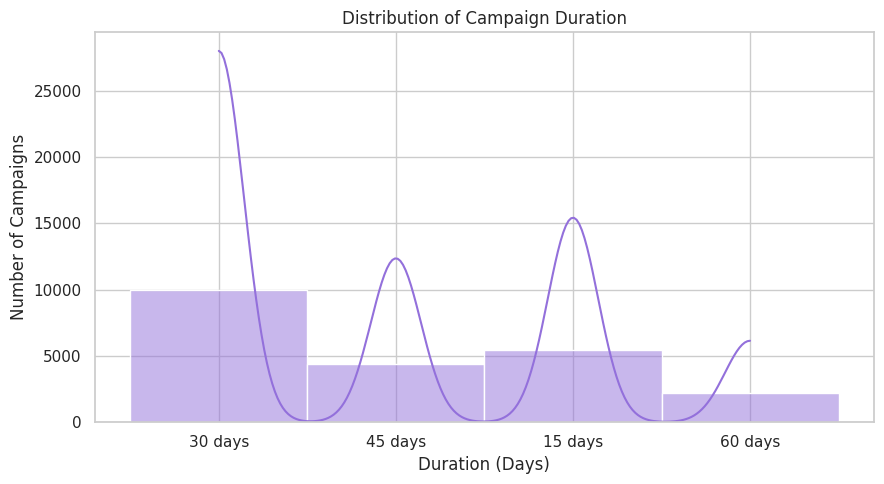

In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Duration",
    bins=15,
    kde=True,
    color="mediumpurple"
)

plt.title("Distribution of Campaign Duration")
plt.xlabel("Duration (Days)")
plt.ylabel("Number of Campaigns")
plt.tight_layout()
plt.show()

3.14 Conversion Rate trend over time for each Company

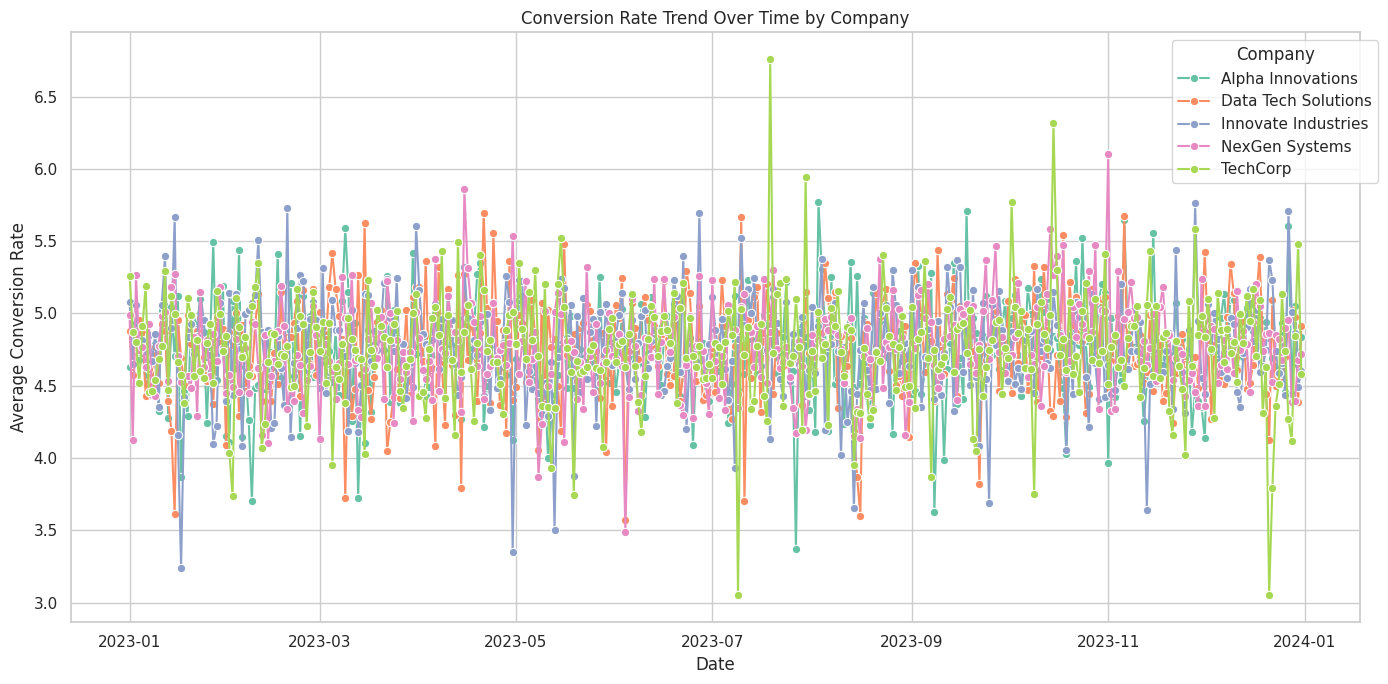

In [17]:
daily_company_conversion = (
    df.groupby(["Date", "Company"], as_index=False)["Conversion_Rate"]
    .mean()
    .sort_values("Date")
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=daily_company_conversion,
    x="Date",
    y="Conversion_Rate",
    hue="Company",
    marker="o",
    errorbar=None
)

plt.title("Conversion Rate Trend Over Time by Company")
plt.xlabel("Date")
plt.ylabel("Average Conversion Rate")
plt.legend(title="Company", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

3.15 Engagement Score trend over time

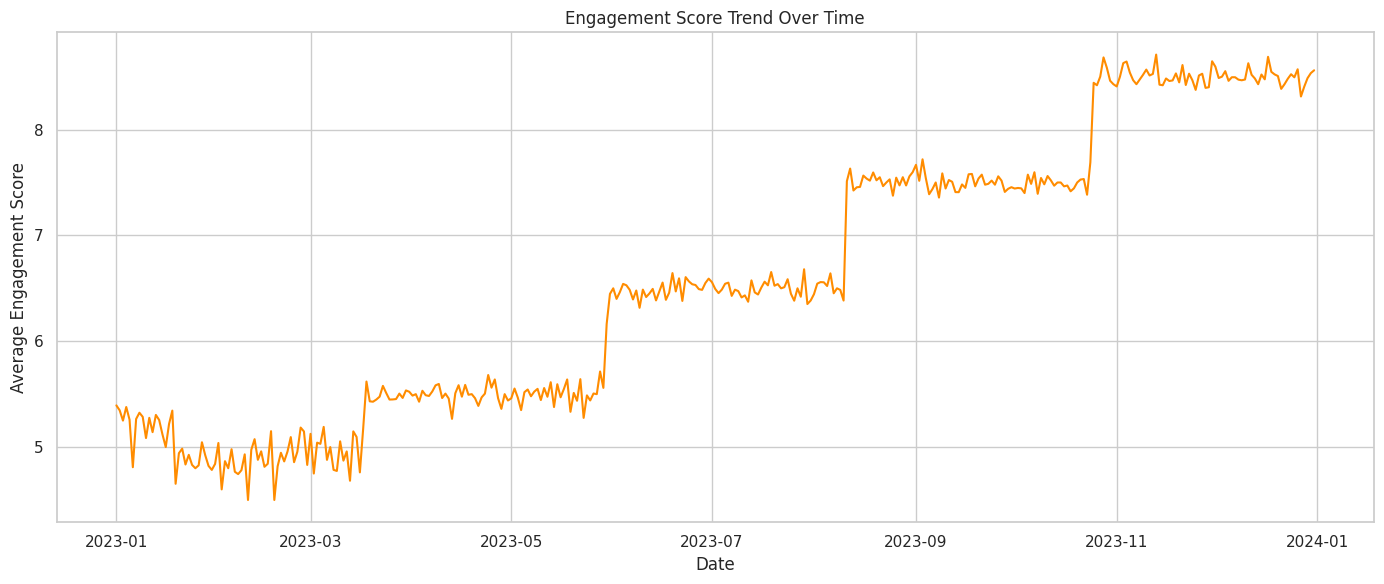

In [18]:
daily_engagement = (
    df.groupby("Date", as_index=False)["Engagement_Score"]
    .mean()
    .sort_values("Date")
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_engagement,
    x="Date",
    y="Engagement_Score",
    color="darkorange"
)

plt.title("Engagement Score Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.tight_layout()
plt.show()

E. Geographic analysis
3.16 Average Acquisition Cost by Location

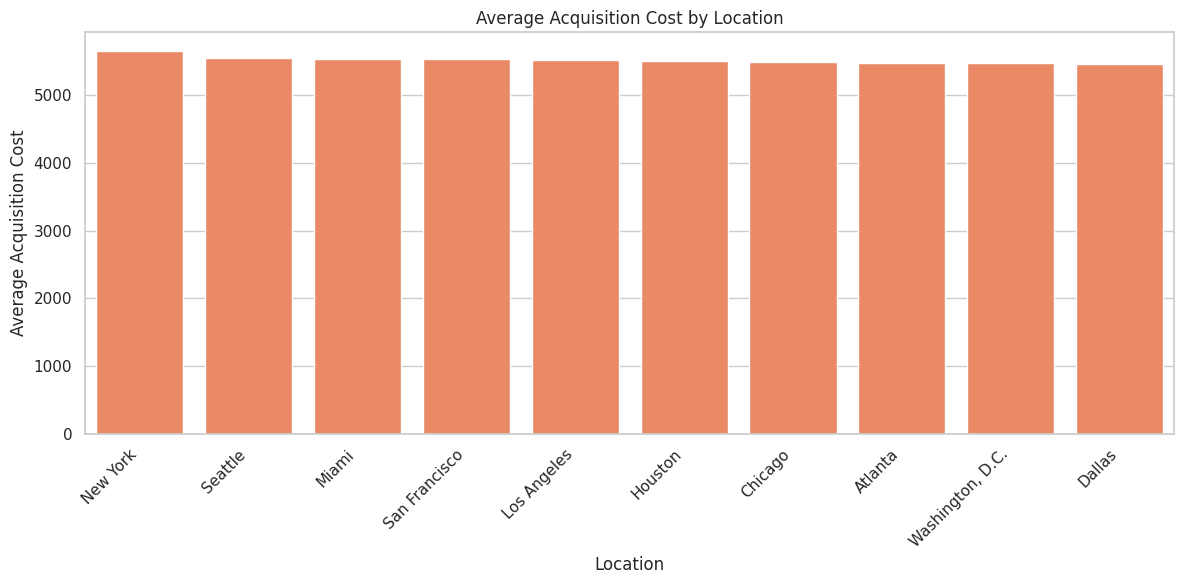

Location with highest average acquisition cost:
Location               New York
Acquisition_Cost    5650.628611
Name: 6, dtype: object


In [19]:
location_cost = (
    df.groupby("Location", as_index=False)["Acquisition_Cost"]
    .mean()
    .sort_values("Acquisition_Cost", ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=location_cost,
    x="Location",
    y="Acquisition_Cost",
    color="coral"
)

plt.title("Average Acquisition Cost by Location")
plt.xlabel("Location")
plt.ylabel("Average Acquisition Cost")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Location with highest average acquisition cost:")
print(location_cost.iloc[0])

3.17 Conversion Rate by Location and Target Audience

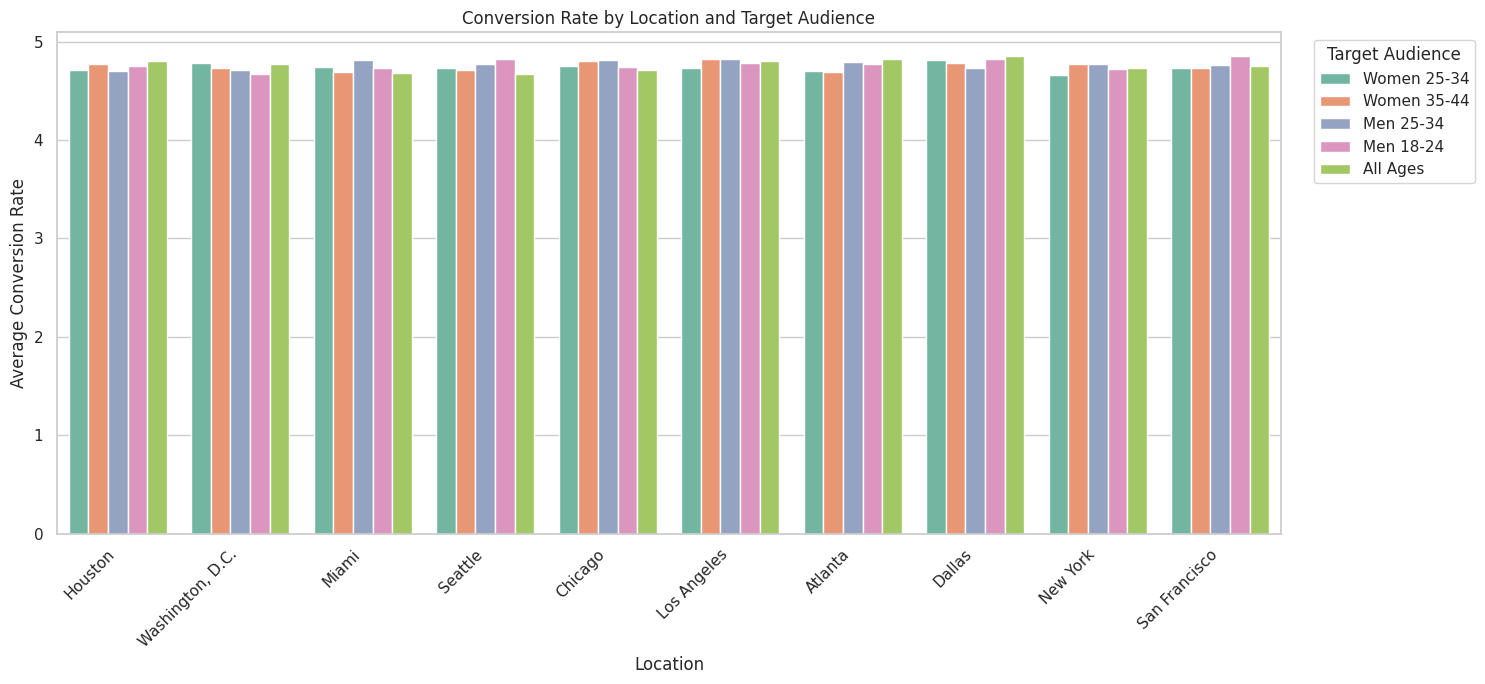

In [20]:
plt.figure(figsize=(15, 7))

sns.barplot(
    data=df,
    x="Location",
    y="Conversion_Rate",
    hue="Target_Audience",
    errorbar=None
)

plt.title("Conversion Rate by Location and Target Audience")
plt.xlabel("Location")
plt.ylabel("Average Conversion Rate")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Target Audience", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

3.18 Proportion of ROI by Location — pie chart

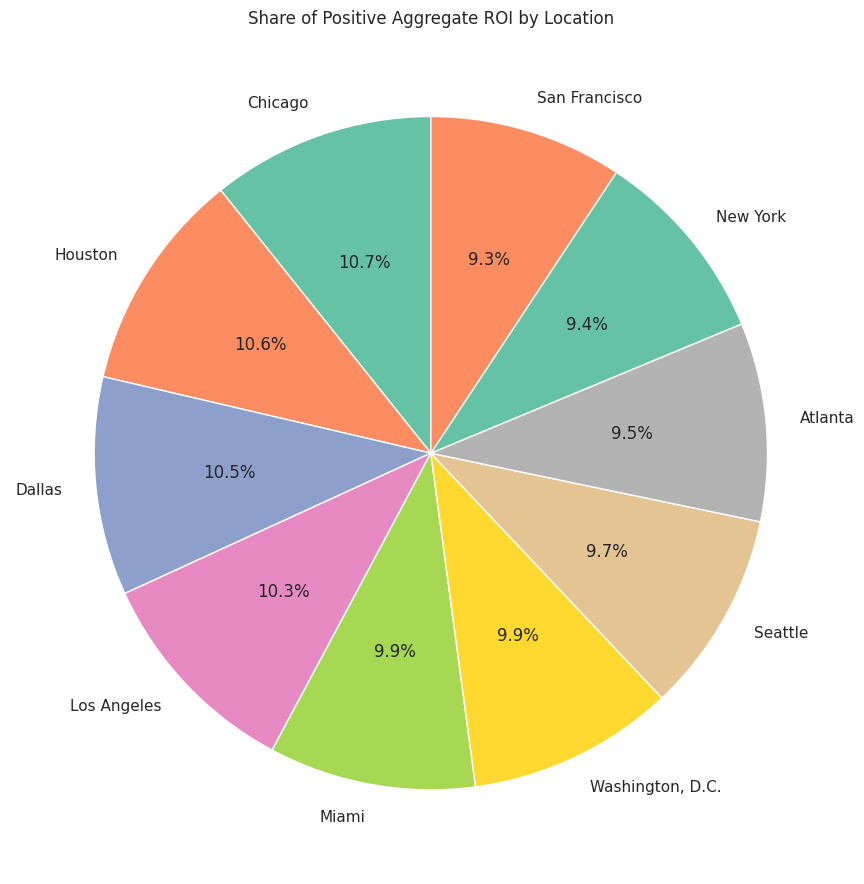

Total ROI by Location:
Location
Chicago             432257.42
Houston             427727.23
Dallas              422771.06
Los Angeles         416718.64
Miami               400086.36
Washington, D.C.    399653.29
Seattle             390251.85
Atlanta             384348.19
New York            380121.73
San Francisco       374367.54
Name: ROI, dtype: float64

Locations with non-positive aggregate ROI:
Series([], Name: ROI, dtype: float64)


In [21]:
location_roi = df.groupby("Location")["ROI"].sum().sort_values(
    ascending=False
)

positive_location_roi = location_roi[location_roi > 0]

plt.figure(figsize=(10, 9))

positive_location_roi.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    ylabel=""
)

plt.title("Share of Positive Aggregate ROI by Location")
plt.tight_layout()
plt.show()

print("Total ROI by Location:")
print(location_roi)

print("\nLocations with non-positive aggregate ROI:")
print(location_roi[location_roi <= 0])

4. Additional summary of findings

In [22]:
print("=" * 55)
print("MARKETING CAMPAIGN ANALYSIS SUMMARY")
print("=" * 55)

# Highest average ROI company
company_avg_roi = df.groupby("Company")["ROI"].mean()
print("\nCompany with highest average ROI:")
print(company_avg_roi.idxmax(), ":", round(company_avg_roi.max(), 2))

# Highest average conversion channel
channel_avg_conversion = df.groupby("Channel_Used")["Conversion_Rate"].mean()
print("\nChannel with highest average Conversion Rate:")
print(
    channel_avg_conversion.idxmax(),
    ":",
    round(channel_avg_conversion.max(), 2)
)

# Highest average conversion language
language_avg_conversion = df.groupby("Language")["Conversion_Rate"].mean()
print("\nLanguage with highest average Conversion Rate:")
print(
    language_avg_conversion.idxmax(),
    ":",
    round(language_avg_conversion.max(), 2)
)

# Highest average engagement campaign type
campaign_avg_engagement = df.groupby("Campaign_Type")["Engagement_Score"].mean()
print("\nCampaign Type with highest average Engagement Score:")
print(
    campaign_avg_engagement.idxmax(),
    ":",
    round(campaign_avg_engagement.max(), 2)
)

# Highest average acquisition cost location
location_avg_cost = df.groupby("Location")["Acquisition_Cost"].mean()
print("\nLocation with highest average Acquisition Cost:")
print(
    location_avg_cost.idxmax(),
    ":",
    round(location_avg_cost.max(), 2)
)

# Correlation between engagement and conversion
corr = df["Engagement_Score"].corr(df["Conversion_Rate"])
print("\nCorrelation between Engagement Score and Conversion Rate:")
print(round(corr, 3))

print("\nAnalysis completed successfully.")

MARKETING CAMPAIGN ANALYSIS SUMMARY

Company with highest average ROI:
Alpha Innovations : 187.8

Channel with highest average Conversion Rate:
Facebook : 4.78

Language with highest average Conversion Rate:
English : 5.01

Campaign Type with highest average Engagement Score:
Social Media : 6.86

Location with highest average Acquisition Cost:
New York : 5650.63

Correlation between Engagement Score and Conversion Rate:
0.011

Analysis completed successfully.


5. Conclusion and report-writing guide

Campaign performance: Explain the relationship between acquisition cost and ROI, and identify the companies with the highest average ROI.

Customer segmentation: Identify the best-performing customer segment for each language and compare conversion rates across audiences.

Channel effectiveness: Determine which channels generate higher conversion rates and engagement scores, and discuss their ROI contributions.

Time-based trends: Describe any increases, decreases, or fluctuations in conversion rates and engagement over time.

Geographic performance: Identify locations with higher average acquisition costs, stronger conversion rates, and greater positive ROI contributions.